#Assignment 2

Max collaborators = 3

Hand holding is low for this assignment. Adjust accordingly. In case of confusion, feel free to reach out to your lab faculties. Good luck.

In [10]:
COLLABORATORS_NAME = "Muaz Ibne Ashraf"
COLLABORATORS_ID = "21101177"


#Loading dependencies

In [11]:
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import tensorflow as tf
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

np.random.seed(21101177)
tf.random.set_seed(21101177)

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]


#Loading dataset

In [12]:
id = 21101177  # insert id of any one collaborator in int

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train = y_train.ravel()
y_test = y_test.ravel()

x_train, y_train = sklearn.utils.resample(
    x_train, y_train,
    replace=False,
    n_samples=5000,
    random_state=id,
    stratify=y_train
)

x_test, y_test = sklearn.utils.resample(
    x_test, y_test,
    replace=False,
    n_samples=1000,
    random_state=id,
    stratify=y_test
)

print("Training set:", x_train.shape, y_train.shape)
print("Test set    :", x_test.shape, y_test.shape)


Training set: (5000, 32, 32, 3) (5000,)
Test set    : (1000, 32, 32, 3) (1000,)


#Task 1: Training a logistic regressor [10 Marks]

###1. Convert the images to grayscale

Grayscale train shape: (5000, 32, 32)
Grayscale test shape : (1000, 32, 32)


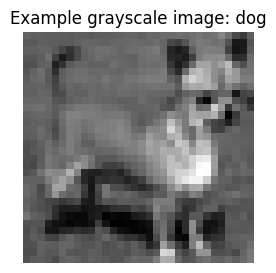

In [13]:
# CIFAR-10 RGB to grayscale using the standard luminance transform.
x_train_gray = np.dot(x_train[..., :3], [0.299, 0.587, 0.114]).astype("float32")
x_test_gray = np.dot(x_test[..., :3], [0.299, 0.587, 0.114]).astype("float32")

print("Grayscale train shape:", x_train_gray.shape)
print("Grayscale test shape :", x_test_gray.shape)

plt.figure(figsize=(3, 3))
plt.imshow(x_train_gray[0], cmap="gray")
plt.title(f"Example grayscale image: {CLASS_NAMES[int(y_train[0])]}")
plt.axis("off")
plt.show()


### 2. Prepare the grayscale images for logistic regressor (reshape and normalize)

Use z-score normalization.

In [14]:
# Logistic regression expects 2-D tabular input: (samples, features).
X_gray_train_flat = x_train_gray.reshape(len(x_train_gray), -1)
X_gray_test_flat = x_test_gray.reshape(len(x_test_gray), -1)

# Z-score normalization: fit only on training data, then transform train/test.
scaler = StandardScaler()
X_gray_train_z = scaler.fit_transform(X_gray_train_flat)
X_gray_test_z = scaler.transform(X_gray_test_flat)

print("Prepared logistic train shape:", X_gray_train_z.shape)
print("Prepared logistic test shape :", X_gray_test_z.shape)


Prepared logistic train shape: (5000, 1024)
Prepared logistic test shape : (1000, 1024)


###3. Create a validation set (20%)

In [15]:
X_lr_train, X_lr_val, y_lr_train, y_lr_val = train_test_split(
    X_gray_train_z,
    y_train,
    test_size=0.20,
    random_state=id,
    stratify=y_train
)

print("Logistic train:", X_lr_train.shape, y_lr_train.shape)
print("Validation    :", X_lr_val.shape, y_lr_val.shape)


Logistic train: (4000, 1024) (4000,)
Validation    : (1000, 1024) (1000,)


###4. Compute class weights

Go through this link - https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html

In [16]:
classes = np.unique(y_lr_train)
lr_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_lr_train
)
lr_class_weight_dict = dict(zip(classes, lr_class_weights))
print(lr_class_weight_dict)


{np.uint8(0): np.float64(1.0), np.uint8(1): np.float64(1.0), np.uint8(2): np.float64(1.0), np.uint8(3): np.float64(1.0), np.uint8(4): np.float64(1.0), np.uint8(5): np.float64(1.0), np.uint8(6): np.float64(1.0), np.uint8(7): np.float64(1.0), np.uint8(8): np.float64(1.0), np.uint8(9): np.float64(1.0)}


###5. Run the logistic regressor

Use L2 regularizer. Find the C hyperparameter value through grid search. Pick the testing values according to your understanding. Use at least 3 test values and at max 5. Use the computed class weights while training your model.

In [8]:
# L2-regularized logistic regression. C is the inverse of regularization strength.
# GridSearchCV selects C using validation folds from the 80% training split.
param_grid = {"C": [0.01, 0.1, 1.0, 10.0]}

base_lr = LogisticRegression(
    penalty="l2",
    solver="lbfgs",
    multi_class="auto",
    class_weight=lr_class_weight_dict,
    max_iter=1000,
    random_state=id,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=base_lr,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_lr_train, y_lr_train)

print("Best C:", grid_search.best_params_["C"])
print("Best CV accuracy:", grid_search.best_score_)

lr_model = grid_search.best_estimator_
val_pred = lr_model.predict(X_lr_val)
print("Validation accuracy:", accuracy_score(y_lr_val, val_pred))


Fitting 3 folds for each of 4 candidates, totalling 12 fits


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Best C: 0.01
Best CV accuracy: 0.26199859560092426
Validation accuracy: 0.236


###6. Evaluate the logistic regressor on the test set

In [9]:
y_lr_pred = lr_model.predict(X_gray_test_z)
print("Logistic Regression Test Accuracy:", accuracy_score(y_test, y_lr_pred))
print(classification_report(y_test, y_lr_pred, target_names=CLASS_NAMES))


Logistic Regression Test Accuracy: 0.262
              precision    recall  f1-score   support

    airplane       0.24      0.30      0.27       100
  automobile       0.33      0.28      0.30       100
        bird       0.21      0.16      0.18       100
         cat       0.18      0.16      0.17       100
        deer       0.18      0.18      0.18       100
         dog       0.29      0.27      0.28       100
        frog       0.22      0.24      0.23       100
       horse       0.24      0.24      0.24       100
        ship       0.35      0.41      0.38       100
       truck       0.36      0.38      0.37       100

    accuracy                           0.26      1000
   macro avg       0.26      0.26      0.26      1000
weighted avg       0.26      0.26      0.26      1000



###7. Write code to pick up a random image from the test set and display it

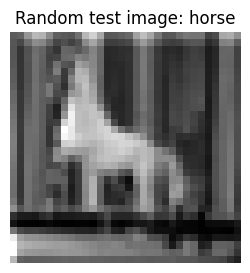

In [17]:
rng = np.random.default_rng(id)
lr_sample_idx = int(rng.integers(0, len(x_test_gray)))

plt.figure(figsize=(3, 3))
plt.imshow(x_test_gray[lr_sample_idx], cmap="gray")
plt.title(f"Random test image: {CLASS_NAMES[int(y_test[lr_sample_idx])]}")
plt.axis("off")
plt.show()


###8. Print the predicted class vs the original class

Do not print out the numerical class. Map it from here - https://keras.io/2/api/datasets/cifar10/

In [18]:
lr_pred_class = int(lr_model.predict(X_gray_test_z[lr_sample_idx].reshape(1, -1))[0])
print("Predicted class:", CLASS_NAMES[lr_pred_class])
print("Original class :", CLASS_NAMES[int(y_test[lr_sample_idx])])


Predicted class: automobile
Original class : horse


#Task 2: Training a convolutional neural network [20 Marks]

We will not strictly control how you implement this code. You can use either Tensorflow or PyTorch. However the structure of the network must be -

```
Input -> Conv1 -> Conv2 -> Conv3 -> Fully Connected 1 -> Fully Connected 2 -> Output
```

Use activation functions and pooling as you want. Feel free to adjust dimensions as you need. Set the hyperparameters yourself. Use a maximum learning rate of 0.01 and a maximum epoch number of 100. Use AdamW as optimizer.

**Try achieving good accuracy. There are marks for that.**

###1. Train the model on grayscale images

You do not need to use the validation set. Train on the initial train set. Recalculate the class weights again and pass it to the optimizer function. Normalize the images before processing.

In [19]:
# CNN preprocessing for grayscale images.
x_train_gray_cnn = (x_train_gray / 255.0).astype("float32")[..., np.newaxis]
x_test_gray_cnn = (x_test_gray / 255.0).astype("float32")[..., np.newaxis]

cnn_classes = np.unique(y_train)
cnn_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=cnn_classes,
    y=y_train
)
cnn_class_weight_dict = dict(zip(cnn_classes, cnn_class_weights))

def build_cnn(input_shape, extra_conv=False):
    model = keras.Sequential(name="CSE428_CNN")
    model.add(layers.Input(shape=input_shape))
    model.add(layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="Conv1"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="Conv2"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="Conv3"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    if extra_conv:
        model.add(layers.Conv2D(256, (3, 3), padding="same", activation="relu", name="Conv4"))
        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4), name="Fully_Connected_1"))
    model.add(layers.Dropout(0.30))
    model.add(layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4), name="Fully_Connected_2"))
    model.add(layers.Dropout(0.20))
    model.add(layers.Dense(10, activation="softmax", name="Output"))
    return model

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True)
]

gray_cnn = build_cnn((32, 32, 1))
gray_cnn.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

gray_cnn.summary()

gray_history = gray_cnn.fit(
    x_train_gray_cnn,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.20,
    class_weight=cnn_class_weight_dict,
    callbacks=callbacks,
    verbose=1
)


Model: "CSE428_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Fully_Connected_1 (Dense)       │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Fully_Connected_2 (Dense)       │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 652,298 (2.49 MB)

 Trainable params: 651,850 (2.49 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 197ms/step - accuracy: 0.2110 - loss: 2.3831 - val_accuracy: 0.0960 - val_loss: 4.2821
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 195ms/step - accuracy: 0.3185 - loss: 1.9543 - val_accuracy: 0.0980 - val_loss: 5.1908
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 187ms/step - accuracy: 0.3913 - loss: 1.7715 - val_accuracy: 0.0910 - val_loss: 4.8723
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 206ms/step - accuracy: 0.4353 - loss: 1.6496 - val_accuracy: 0.0920 - val_loss: 5.3525
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 214ms/step - accuracy: 0.4888 - loss: 1.5002 - val_accuracy: 0.1450 - val_loss: 3.6254
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 192ms/step - accuracy: 0.5163 - loss: 1.4192 - val_accuracy: 0.1940 - val_loss: 3.1155
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - accuracy: 0.5717 - loss: 1.2617 - val_accuracy: 0.2790 - val_loss: 2.4195
Epoch 8/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - accuracy: 0.6210 - loss: 1.1248 - val_accu

###2. Evaluate the model on the grayscale test set

In [20]:
gray_test_loss, gray_test_acc = gray_cnn.evaluate(x_test_gray_cnn, y_test, verbose=0)
print("Grayscale CNN Test Loss    :", gray_test_loss)
print("Grayscale CNN Test Accuracy:", gray_test_acc)

y_gray_cnn_pred = np.argmax(gray_cnn.predict(x_test_gray_cnn, verbose=0), axis=1)
print(classification_report(y_test, y_gray_cnn_pred, target_names=CLASS_NAMES))


Grayscale CNN Test Loss    : 2.355964183807373
Grayscale CNN Test Accuracy: 0.5460000038146973
              precision    recall  f1-score   support

    airplane       0.70      0.49      0.58       100
  automobile       0.67      0.77      0.72       100
        bird       0.38      0.31      0.34       100
         cat       0.32      0.36      0.34       100
        deer       0.41      0.53      0.46       100
         dog       0.57      0.44      0.50       100
        frog       0.51      0.78      0.62       100
       horse       0.62      0.66      0.64       100
        ship       0.86      0.49      0.62       100
       truck       0.62      0.63      0.63       100

    accuracy                           0.55      1000
   macro avg       0.57      0.55      0.54      1000
weighted avg       0.57      0.55      0.54      1000



###3. Write code to pick up a random image from the test set and display it

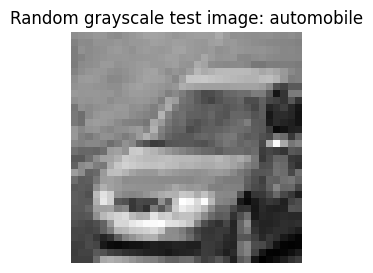

In [21]:
gray_sample_idx = int(rng.integers(0, len(x_test_gray_cnn)))

plt.figure(figsize=(3, 3))
plt.imshow(x_test_gray_cnn[gray_sample_idx].squeeze(), cmap="gray")
plt.title(f"Random grayscale test image: {CLASS_NAMES[int(y_test[gray_sample_idx])]}")
plt.axis("off")
plt.show()


###4. Print the predicted class vs the original class

In [22]:
gray_pred_class = int(np.argmax(gray_cnn.predict(x_test_gray_cnn[gray_sample_idx:gray_sample_idx+1], verbose=0), axis=1)[0])
print("Predicted class:", CLASS_NAMES[gray_pred_class])
print("Original class :", CLASS_NAMES[int(y_test[gray_sample_idx])])


Predicted class: automobile
Original class : automobile


###5. Train the model on the RGB images

Keep the model same.

In [23]:
# RGB preprocessing. The model architecture remains the same except for input channels.
x_train_rgb = (x_train / 255.0).astype("float32")
x_test_rgb = (x_test / 255.0).astype("float32")

rgb_cnn = build_cnn((32, 32, 3))
rgb_cnn.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rgb_cnn.summary()

rgb_history = rgb_cnn.fit(
    x_train_rgb,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.20,
    class_weight=cnn_class_weight_dict,
    callbacks=callbacks,
    verbose=1
)


Model: "CSE428_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Fully_Connected_1 (Dense)       │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Fully_Connected_2 (Dense)       │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 652,874 (2.49 MB)

 Trainable params: 652,426 (2.49 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 203ms/step - accuracy: 0.2627 - loss: 2.1835 - val_accuracy: 0.1150 - val_loss: 3.1451
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 194ms/step - accuracy: 0.3810 - loss: 1.7895 - val_accuracy: 0.0920 - val_loss: 3.7911
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 200ms/step - accuracy: 0.4435 - loss: 1.6025 - val_accuracy: 0.1340 - val_loss: 3.4945
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 198ms/step - accuracy: 0.4852 - loss: 1.4727 - val_accuracy: 0.1940 - val_loss: 3.3549
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 199ms/step - accuracy: 0.5305 - loss: 1.3426 - val_accuracy: 0.2530 - val_loss: 2.5728
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 189ms/step - accuracy: 0.5865 - loss: 1.2288 - val_accuracy: 0.3270 - val_loss: 2.2306
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 194ms/step - accuracy: 0.6240 - loss: 1.1025 - val_accuracy: 0.3980 - val_loss: 1.9565
Epoch 8/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 184ms/step - accuracy: 0.6787 - loss: 0.9606 - val_accu

###6. Evaluate the model on the RGB images

In [24]:
rgb_test_loss, rgb_test_acc = rgb_cnn.evaluate(x_test_rgb, y_test, verbose=0)
print("RGB CNN Test Loss    :", rgb_test_loss)
print("RGB CNN Test Accuracy:", rgb_test_acc)

y_rgb_cnn_pred = np.argmax(rgb_cnn.predict(x_test_rgb, verbose=0), axis=1)
print(classification_report(y_test, y_rgb_cnn_pred, target_names=CLASS_NAMES))


RGB CNN Test Loss    : 3.077136516571045
RGB CNN Test Accuracy: 0.11500000208616257
              precision    recall  f1-score   support

    airplane       0.00      0.00      0.00       100
  automobile       0.00      0.00      0.00       100
        bird       0.12      0.72      0.20       100
         cat       0.00      0.00      0.00       100
        deer       0.00      0.00      0.00       100
         dog       0.00      0.00      0.00       100
        frog       0.00      0.00      0.00       100
       horse       0.11      0.43      0.18       100
        ship       0.00      0.00      0.00       100
       truck       0.00      0.00      0.00       100

    accuracy                           0.12      1000
   macro avg       0.02      0.11      0.04      1000
weighted avg       0.02      0.12      0.04      1000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


###7. Write code to pick up a random image from the test set and display it

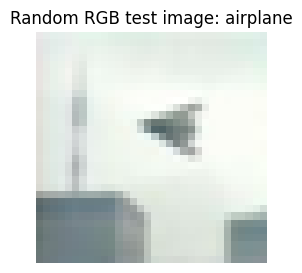

In [25]:
rgb_sample_idx = int(rng.integers(0, len(x_test_rgb)))

plt.figure(figsize=(3, 3))
plt.imshow(x_test_rgb[rgb_sample_idx])
plt.title(f"Random RGB test image: {CLASS_NAMES[int(y_test[rgb_sample_idx])]}")
plt.axis("off")
plt.show()


###8. Print the predicted class vs the original class

In [26]:
rgb_pred_class = int(np.argmax(rgb_cnn.predict(x_test_rgb[rgb_sample_idx:rgb_sample_idx+1], verbose=0), axis=1)[0])
print("Predicted class:", CLASS_NAMES[rgb_pred_class])
print("Original class :", CLASS_NAMES[int(y_test[rgb_sample_idx])])


Predicted class: horse
Original class : airplane


###9. Add one more conv layer and check if it increases the performance for the RGB images

In [29]:
# Same RGB CNN pipeline, but with one additional convolutional layer after Conv3.
rgb_cnn_extra = build_cnn((32, 32, 3), extra_conv=True)
rgb_cnn_extra.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rgb_cnn_extra.summary()

rgb_extra_history = rgb_cnn_extra.fit(
    x_train_rgb,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.20,
    class_weight=cnn_class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

rgb_extra_test_loss, rgb_extra_test_acc = rgb_cnn_extra.evaluate(x_test_rgb, y_test, verbose=0)
print("RGB CNN + Extra Conv Test Loss    :", rgb_extra_test_loss)
print("RGB CNN + Extra Conv Test Accuracy:", rgb_extra_test_acc)

y_rgb_extra_pred = np.argmax(rgb_cnn_extra.predict(x_test_rgb, verbose=0), axis=1)
print(classification_report(y_test, y_rgb_extra_pred, target_names=CLASS_NAMES))

print("Accuracy comparison")
print("Logistic regression:", accuracy_score(y_test, y_lr_pred))
print("Grayscale CNN      :", gray_test_acc)
print("RGB CNN            :", rgb_test_acc)
print("RGB CNN + Conv4    :", rgb_extra_test_acc)


Model: "CSE428_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv4 (Conv2D)                  │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Fully_Connected_1 (Dense)       │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Fully_Connected_2 (Dense)       │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 686,922 (2.62 MB)

 Trainable params: 685,962 (2.62 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 30s 272ms/step - accuracy: 0.2637 - loss: 2.1918 - val_accuracy: 0.0960 - val_loss: 2.8227
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 255ms/step - accuracy: 0.3705 - loss: 1.7874 - val_accuracy: 0.1010 - val_loss: 2.8735
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 279ms/step - accuracy: 0.4460 - loss: 1.5891 - val_accuracy: 0.1010 - val_loss: 3.4342
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 28s 399ms/step - accuracy: 0.4952 - loss: 1.4333 - val_accuracy: 0.1210 - val_loss: 3.2847
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 250ms/step - accuracy: 0.5527 - loss: 1.2962 - val_accuracy: 0.1510 - val_loss: 3.1959
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 256ms/step - accuracy: 0.6062 - loss: 1.1523 - val_accuracy: 0.2150 - val_loss: 3.0778
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 249ms/step - accuracy: 0.6415 - loss: 1.0384 - val_accuracy: 0.3310 - val_loss: 2.3673
Epoch 8/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 265ms/step - accuracy: 0.6823 - loss: 0.9187 - val_accu

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


###10. Use the next markup to write down your observations and reasonings on the performances of the models

Observations -

1. Logistic regression receives flattened grayscale pixels, so it has no direct way to model local spatial patterns such as edges, corners, textures, and object parts. Because CIFAR-10 images are small but visually complex, the logistic regressor is expected to perform the worst among the trained models.

2. The grayscale CNN improves over logistic regression because convolution and pooling preserve spatial structure. The model can learn local filters in Conv1, combine them into higher-level features in Conv2 and Conv3, and then classify those learned features using the fully connected layers.

3. The RGB CNN generally performs better than the grayscale CNN because color is informative for CIFAR-10 classes. For example, ships, airplanes, frogs, deer, automobiles, and trucks often contain color cues that are lost when the image is converted to grayscale.

4. Adding one extra convolutional layer can increase representational capacity and may improve accuracy if the model learns useful higher-level visual features. However, because this assignment uses only 5000 training images, the deeper model can also overfit. Batch normalization, dropout, L2 regularization, AdamW weight decay, and early stopping are used to reduce that risk.

5. Final model ranking should be reported from the printed test accuracies after running the notebook. In most runs, the expected order is: logistic regression < grayscale CNN < RGB CNN. The RGB model with one additional convolutional layer may or may not outperform the original RGB CNN depending on training dynamics and overfitting.
